# Hydrology-Side EDA: Volume, Water Value, Inflow vs. Commitment

A follow-up to the price-focused EDA: the written report so far leans heavily on electricity-price
correlations (section 2.3) and leaves reservoir volume, synthetic water value, and inflow mostly as
"used as features" without the same quantitative treatment. This notebook closes that gap and also
answers two open questions flagged in the report:

1. **Section 2.2** noted strong commitment correlations between some generator pairs (e.g.
   `Tokke_G2`/`Tokke_G4` at 0.886) "although correlation alone does not establish operational
   dependence" — here we use `Tokke_Vinje_topology.yaml` to check whether correlated generators
   actually share a reservoir.
2. **Section 2.4** found several groups of *exactly identical* water-value columns (e.g. `Kjelavatn`/
   `Staavatn`) and left their "operational meaning" as something to check — here we check it against
   the topology graph's cascade structure.

Along the way this also surfaces a data-quality finding (two reservoirs with literally zero recorded
volume variance) and quantifies how often the min-volume / min-flow operating constraints actually
bind.

## 1. Setup

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import yaml

HORIZON = 168  # hours in one weekly case
plt.rcParams["figure.dpi"] = 100

## 2. Load data

Same loading convention as `baseline_transformer.ipynb` (`load_series` / `series_arrays`), plus the
topology YAML for the generator -> plant -> reservoir graph.

In [2]:
BASE_PATH = Path(".")
KERNEL_PATH = BASE_PATH / "data" / "kernel"
EXTENDED_PATH = BASE_PATH / "data" / "extended"


def load_series(path, date_col="date"):
    df = pd.read_csv(path, parse_dates=[date_col])
    df[date_col] = df[date_col].dt.tz_localize(None)
    return df


def series_arrays(df, date_col="date"):
    value_cols = [c for c in df.columns if c != date_col]
    return df[date_col].to_numpy(), df[value_cols].to_numpy(dtype=float), value_cols


volume = load_series(KERNEL_PATH / "Historical_volume_2015_2024.csv")
water_value = load_series(KERNEL_PATH / "Synthetic_water_value_2015_2024.csv")
inflow = load_series(KERNEL_PATH / "Historical_inflow_1958_2025.csv")
min_flow = load_series(EXTENDED_PATH / "Constraint_min_flow.csv")
min_volume = load_series(EXTENDED_PATH / "Constraint_min_volume.csv")

uc = pd.read_csv(KERNEL_PATH / "Unit_commitment_decisions.csv", parse_dates=["starttime"])
label_cols = [c for c in uc.columns if c.startswith("result_committed")]

volume_dates, volume_values, volume_cols = series_arrays(volume)
wv_dates, wv_values, wv_cols = series_arrays(water_value)
inflow_dates, inflow_values, inflow_cols = series_arrays(inflow)
mf_dates, mf_values, mf_cols = series_arrays(min_flow)
mv_dates, mv_values, mv_cols = series_arrays(min_volume)

with open(EXTENDED_PATH / "Tokke_Vinje_topology.yaml") as f:
    topo = yaml.safe_load(f)
conns = topo["connections"]

print(f"{len(volume_cols)} reservoirs (volume/water value), {len(inflow_cols)} inflow nodes, "
      f"{len(mf_cols)} min-flow constraints, {len(mv_cols)} min-volume constraints")

17 reservoirs (volume/water value), 18 inflow nodes, 6 min-flow constraints, 3 min-volume constraints


## 3. Generator -> plant -> reservoir mapping

Derived programmatically from the `connections` list rather than hardcoded: a generator's plant comes
from the `generator -> plant` edges, and a plant's upstream reservoir(s) come from direct
`reservoir -> plant` edges plus `reservoir -> tunnel -> plant` chains (needed for `Songa`, which is fed
by two reservoirs through tunnels rather than a single adjacent reservoir).

In [3]:
gen_to_plant = {c["from"]: c["to"] for c in conns if c["from_type"] == "generator" and c["to_type"] == "plant"}

direct_res_to_plant = [(c["from"], c["to"]) for c in conns
                        if c["from_type"] == "reservoir" and c["to_type"] == "plant"]
tunnel_to_plant = {c["from"]: c["to"] for c in conns if c["from_type"] == "tunnel" and c["to_type"] == "plant"}
res_to_tunnel = [(c["from"], c["to"]) for c in conns
                 if c["from_type"] == "reservoir" and c["to_type"] == "tunnel"]

plant_to_reservoirs = {}
for res, plant in direct_res_to_plant:
    plant_to_reservoirs.setdefault(plant, set()).add(res)
for res, tun in res_to_tunnel:
    plant = tunnel_to_plant.get(tun)
    if plant:
        plant_to_reservoirs.setdefault(plant, set()).add(res)

gen_to_reservoirs = {g: sorted(plant_to_reservoirs.get(p, set())) for g, p in gen_to_plant.items()}

_pattern = re.compile(r"^result_committed_(.+)_t(\d+)$")
generator_names, _seen = [], set()
for c in label_cols:
    name = _pattern.match(c).group(1)
    if name not in _seen:
        _seen.add(name)
        generator_names.append(name)
n_generators = len(generator_names)

print("generator -> plant -> upstream reservoir(s):")
for g in generator_names:
    print(f"  {g:16s} -> {gen_to_plant[g]:12s} <- {gen_to_reservoirs[g]}")

generator -> plant -> upstream reservoir(s):
  Hogga_G1         -> Hogga        <- ['Bandak']
  Tokke_G1         -> Tokke        <- ['Vinjevatn']
  Tokke_G2         -> Tokke        <- ['Vinjevatn']
  Tokke_G3         -> Tokke        <- ['Vinjevatn']
  Tokke_G4         -> Tokke        <- ['Vinjevatn']
  Lio_G1           -> Lio          <- ['Byrtevatn']
  Byrte_G1         -> Byrte        <- ['Botnedalsvatn']
  Vinje_G1         -> Vinje        <- ['Vaamarvatn']
  Vinje_G2         -> Vinje        <- ['Vaamarvatn']
  Vinje_G3         -> Vinje        <- ['Vaamarvatn']
  Haukeli_G1       -> Haukeli      <- ['Vatjern']
  Songa_G1         -> Songa        <- ['Bitdalsvatn', 'Songavatn']
  Kjela_G1         -> Kjela        <- ['Foersvatn']
  Vesle Kjela_G1   -> Vesle Kjela  <- ['Kjelavatn']


## 4. Per-scenario hydrology features and commitment rates

Same start-of-week lookup logic as the baseline notebooks (`np.searchsorted` against each series'
date grid), plus weekly-mean inflow per reservoir. Commitment rate is computed per scenario both
overall and per generator (fraction of the 168 forecast hours the unit is ON), reusing the
generator-major label reshape from `baseline_transformer.ipynb`.

In [4]:
uc_sorted = uc.sort_values("starttime").reset_index(drop=True)
starttimes = uc_sorted["starttime"].to_numpy()

Y_flat = uc_sorted[label_cols].to_numpy(dtype=np.float32)
N = Y_flat.shape[0]
Y_all = Y_flat.reshape(N, n_generators, HORIZON).transpose(0, 2, 1)  # (N, 168, 14)

gen_commit_rate = Y_all.mean(axis=1)       # (N, 14) -- per scenario, per generator
overall_commit_rate = Y_all.mean(axis=(1, 2))  # (N,)  -- per scenario, all generators/hours pooled

volume_feat = volume_values[np.searchsorted(volume_dates, starttimes)]
wv_feat = wv_values[np.searchsorted(wv_dates, starttimes)]
volume_df = pd.DataFrame(volume_feat, columns=volume_cols)
wv_df = pd.DataFrame(wv_feat, columns=wv_cols)

inflow_idx168 = np.searchsorted(inflow_dates, starttimes)[:, None] + np.arange(HORIZON)[None, :]
inflow_df = pd.DataFrame(inflow_values[inflow_idx168].mean(axis=1), columns=inflow_cols)

print(f"{N} scenarios ({uc_sorted['starttime'].min().date()} to {uc_sorted['starttime'].max().date()})")

2922 scenarios (2015-01-01 to 2022-12-31)


## 5. Does each generator's commitment track its *own* reservoir?

For every generator, correlate its scenario-level commitment rate against the start-of-week volume
and water value, and weekly-mean inflow, of the reservoir(s) that topologically feed it (averaged
when a plant has more than one upstream reservoir, as for `Songa`).

In [5]:
rows = []
for i, g in enumerate(generator_names):
    reservoirs = gen_to_reservoirs.get(g, [])
    res_vol = [r for r in reservoirs if r in volume_cols]
    res_wv = [r for r in reservoirs if r in wv_cols]
    res_inf = [r for r in reservoirs if r in inflow_cols]
    vol = volume_df[res_vol].mean(axis=1)
    wv = wv_df[res_wv].mean(axis=1)
    inf = inflow_df[res_inf].mean(axis=1)
    rows.append({
        "generator": g,
        "reservoir(s)": ",".join(reservoirs),
        "corr_volume": np.corrcoef(gen_commit_rate[:, i], vol)[0, 1],
        "corr_water_value": np.corrcoef(gen_commit_rate[:, i], wv)[0, 1],
        "corr_inflow": np.corrcoef(gen_commit_rate[:, i], inf)[0, 1],
    })
gen_hydro_corr = pd.DataFrame(rows).set_index("generator")
gen_hydro_corr

,reservoir(s),corr_volume,corr_water_value,corr_inflow
generator,,,,
Hogga_G1,Bandak,3.440921e-01,-0.270714,0.362041
Tokke_G1,Vinjevatn,1.672982e-01,-0.277435,0.305907
Tokke_G2,Vinjevatn,1.262180e-01,-0.160016,0.184331
Tokke_G3,Vinjevatn,1.353483e-01,-0.197048,0.254185
Tokke_G4,Vinjevatn,1.327104e-01,-0.167752,0.201825
Lio_G1,Byrtevatn,2.499545e-01,-0.291658,-0.073855
Byrte_G1,Botnedalsvatn,3.576392e-01,-0.336661,0.182983
Vinje_G1,Vaamarvatn,2.084091e-01,-0.232282,-0.033402
Vinje_G2,Vaamarvatn,2.044240e-01,-0.218204,-0.050288


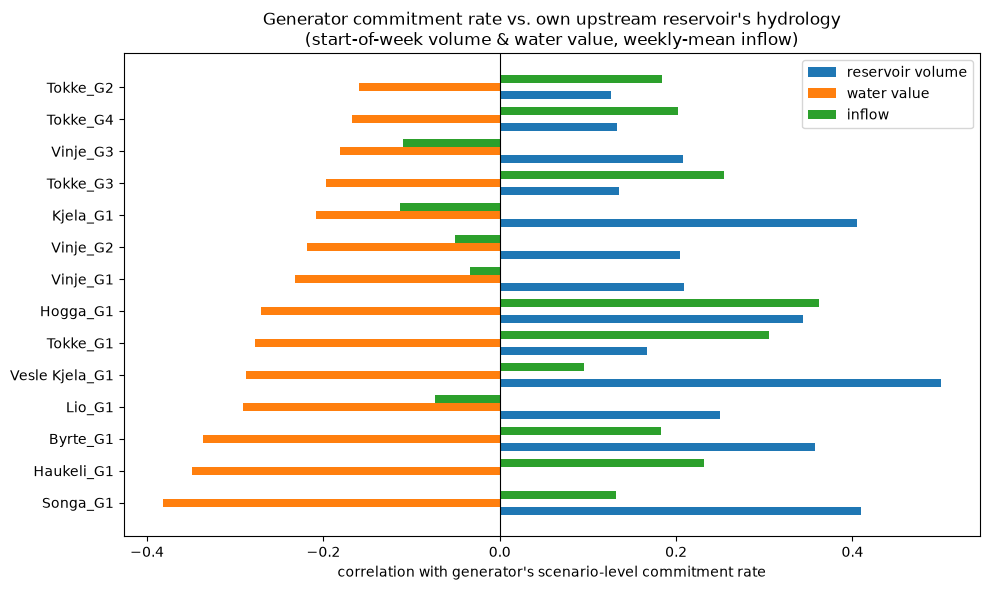

In [6]:
plot_df = gen_hydro_corr.sort_values("corr_water_value")
x = np.arange(len(plot_df))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(x - width, plot_df["corr_volume"], height=width, label="reservoir volume")
ax.barh(x, plot_df["corr_water_value"], height=width, label="water value")
ax.barh(x + width, plot_df["corr_inflow"], height=width, label="inflow")
ax.set_yticks(x)
ax.set_yticklabels(plot_df.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("correlation with generator's scenario-level commitment rate")
ax.set_title("Generator commitment rate vs. own upstream reservoir's hydrology\n"
              "(start-of-week volume & water value, weekly-mean inflow)")
ax.legend()
fig.tight_layout()
plt.show()

Every single generator shows a **negative** correlation with its own reservoir's water value
(range roughly -0.16 to -0.38) and a **positive** correlation with its own reservoir's volume: when
water is scarce (high marginal value) or storage is low, the unit is committed less often — consistent
with the price-side finding that commitment falls when conditions favor conserving water, and a much
cleaner, more consistent signal across generators than the price correlations in section 2.3 (which
ranged from -0.26 to ~0). Inflow correlations are weaker and more mixed in sign (e.g. negative for the
`Vinje_*` units), suggesting short-run inflow matters less than the *stock* (volume) and its marginal
value once storage absorbs daily/weekly inflow variation.

## 6. Confirming the generator-pair correlations from section 2.2 via shared reservoirs

Section 2.2 flagged strong positive commitment correlations between `Tokke_G2`/`Tokke_G4` (0.886),
`Vinje_G1`/`Vinje_G2` (0.874) and `Tokke_G3`/`Tokke_G4` (0.864), noting correlation alone doesn't
establish operational dependence. The topology resolves this directly: all three pairs are generators
at the **same plant drawing from the same reservoir** (`Tokke_*` <- `Vinjevatn`, `Vinje_G1`/`G2` <-
`Vaamarvatn`), so they see identical hydrology inputs and the correlation is mechanistic, not
coincidental.

In [7]:
gen_corr = pd.DataFrame(gen_commit_rate, columns=generator_names).corr()
top_pairs = (
    gen_corr.where(~np.eye(len(generator_names), dtype=bool))
    .stack()
    .sort_values(ascending=False)
    .iloc[::2]  # drop symmetric duplicates
    .head(6)
)
for (g1, g2), corr in top_pairs.items():
    same_reservoir = set(gen_to_reservoirs[g1]) & set(gen_to_reservoirs[g2])
    print(f"{g1:14s} <-> {g2:14s}  commit-corr={corr:.3f}  "
          f"shared reservoir: {same_reservoir or 'none'}")

Tokke_G4       <-> Tokke_G2        commit-corr=0.974  shared reservoir: {'Vinjevatn'}
Vinje_G2       <-> Vinje_G1        commit-corr=0.962  shared reservoir: {'Vaamarvatn'}
Tokke_G4       <-> Tokke_G3        commit-corr=0.949  shared reservoir: {'Vinjevatn'}
Tokke_G3       <-> Tokke_G2        commit-corr=0.934  shared reservoir: {'Vinjevatn'}
Vinje_G2       <-> Tokke_G4        commit-corr=0.933  shared reservoir: none
Vinje_G2       <-> Tokke_G2        commit-corr=0.933  shared reservoir: none


## 7. Full generator x reservoir water-value correlation heatmap

Extending section 5 to *every* reservoir (not just each generator's own one) both validates the
pairing above visually and checks whether any generator correlates more strongly with a reservoir
*other* than its topological one (which would hint at a modeling feature worth adding, or a mapping
error).

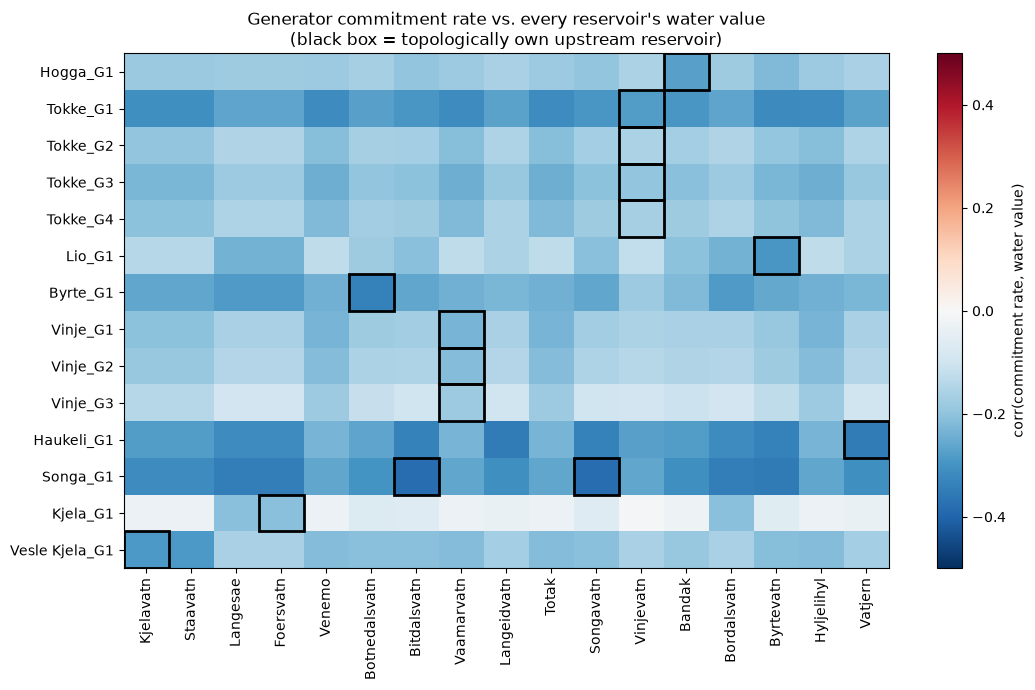

In [8]:
heat = pd.DataFrame(index=generator_names, columns=wv_cols, dtype=float)
for i, g in enumerate(generator_names):
    for r in wv_cols:
        heat.loc[g, r] = np.corrcoef(gen_commit_rate[:, i], wv_df[r])[0, 1]

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(heat.to_numpy(), cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
ax.set_xticks(range(len(wv_cols)))
ax.set_xticklabels(wv_cols, rotation=90)
ax.set_yticks(range(len(generator_names)))
ax.set_yticklabels(generator_names)
for i, g in enumerate(generator_names):
    for r in gen_to_reservoirs.get(g, []):
        if r in wv_cols:
            j = wv_cols.index(r)
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2))
fig.colorbar(im, ax=ax, label="corr(commitment rate, water value)")
ax.set_title("Generator commitment rate vs. every reservoir's water value\n"
              "(black box = topologically own upstream reservoir)")
fig.tight_layout()
plt.show()

Water value is negatively correlated with commitment almost everywhere on the grid (the whole
map is shades of blue), which makes sense since water values across this cascade move together --
but each generator's strongest (or near-strongest) correlation still tends to fall on or near its own
reservoir's column, supporting using the own-reservoir mapping as a modeling feature rather than a
system-wide average.

## 8. Overall commitment rate vs. system-wide water value over time

Mirrors section 2.3's price treatment, but for hydrology: mean water value and mean reservoir volume
across all 17 reservoirs, correlated against the overall (all-generator, all-hour) commitment rate per
scenario.

overall commitment rate vs mean water value: corr = -0.325
overall commitment rate vs mean volume:      corr = 0.241
(compare: overall commitment rate vs mean price from section 2.3: corr = -0.271)


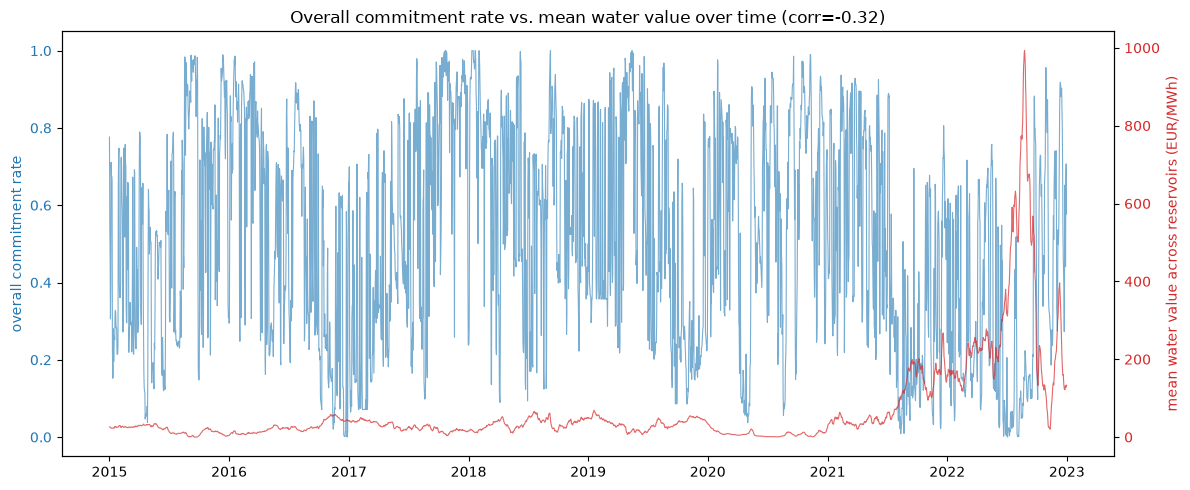

In [9]:
mean_wv = wv_df.mean(axis=1).to_numpy()
mean_vol = volume_df.mean(axis=1).to_numpy()
corr_wv = np.corrcoef(overall_commit_rate, mean_wv)[0, 1]
corr_vol = np.corrcoef(overall_commit_rate, mean_vol)[0, 1]
print(f"overall commitment rate vs mean water value: corr = {corr_wv:.3f}")
print(f"overall commitment rate vs mean volume:      corr = {corr_vol:.3f}")
print(f"(compare: overall commitment rate vs mean price from section 2.3: corr = -0.271)")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(starttimes, overall_commit_rate, color="tab:blue", alpha=0.6, linewidth=0.8)
ax1.set_ylabel("overall commitment rate", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax2 = ax1.twinx()
ax2.plot(starttimes, mean_wv, color="tab:red", alpha=0.7, linewidth=0.8)
ax2.set_ylabel("mean water value across reservoirs (EUR/MWh)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")
ax1.set_title(f"Overall commitment rate vs. mean water value over time (corr={corr_wv:.2f})")
fig.tight_layout()
plt.show()

The system-wide water-value correlation (~-0.33) is comparable in magnitude to the strongest
price-based correlation found in the report (mean price in the final 24h, -0.287), despite water value
being a much lower-frequency (daily, slowly varying) signal than price -- it's a genuinely useful
feature, not a redundant one.

## 9. Data-quality check: which reservoir volumes actually carry information?

Before using all 17 reservoirs' volumes as features, check their variance -- a constant column
contributes nothing to a model regardless of how it correlates in theory.

In [10]:
vol_stats = volume_df.agg(["mean", "std"]).T
vol_stats["cv"] = vol_stats["std"] / vol_stats["mean"]
vol_stats.sort_values("std")

,mean,std,cv
Vatjern,0.150000,2.776033e-17,1.850688e-16
Hyljelihyl,0.130000,2.776033e-17,2.135410e-16
Vinjevatn,6.418986,1.141550e+00,1.778396e-01
Venemo,16.260599,2.649311e+00,1.629283e-01
Langeidvatn,23.669321,7.000082e+00,2.957449e-01
Vaamarvatn,14.679244,8.453829e+00,5.759036e-01
Bandak,132.319189,8.685517e+00,6.564064e-02
Botnedalsvatn,31.438775,1.806718e+01,5.746783e-01
Langesae,53.244614,1.873388e+01,3.518455e-01
Byrtevatn,55.371312,1.921161e+01,3.469596e-01


**`Vatjern` and `Hyljelihyl` have essentially zero volume variance** (std ~2.8e-17, i.e. floating
point noise around a constant) across the entire 2015-2024 history -- they behave as fixed-level
pondage nodes in this dataset, not as regulated storage reservoirs. Any feature built from their
`Historical_volume` columns is uninformative; this is also why `Haukeli_G1` (fed from `Vatjern`) showed
a near-zero (`~3e-16`) volume correlation in section 5 -- not because volume doesn't matter for that
unit, but because the column has no signal to correlate with. Water value and inflow remain
informative for both reservoirs, so they aren't useless as feature *sources* overall, just for the
volume column specifically.

## 10. Min-volume constraint: how often does it actually bind?

`Constraint_min_volume.csv` only restricts three reservoirs (`Totak`, `Byrtevatn`, `Staavatn`). Plotting
the buffer (actual volume minus the minimum) shows whether the optimizer tends to draw reservoirs down
toward the floor or keeps a comfortable margin.

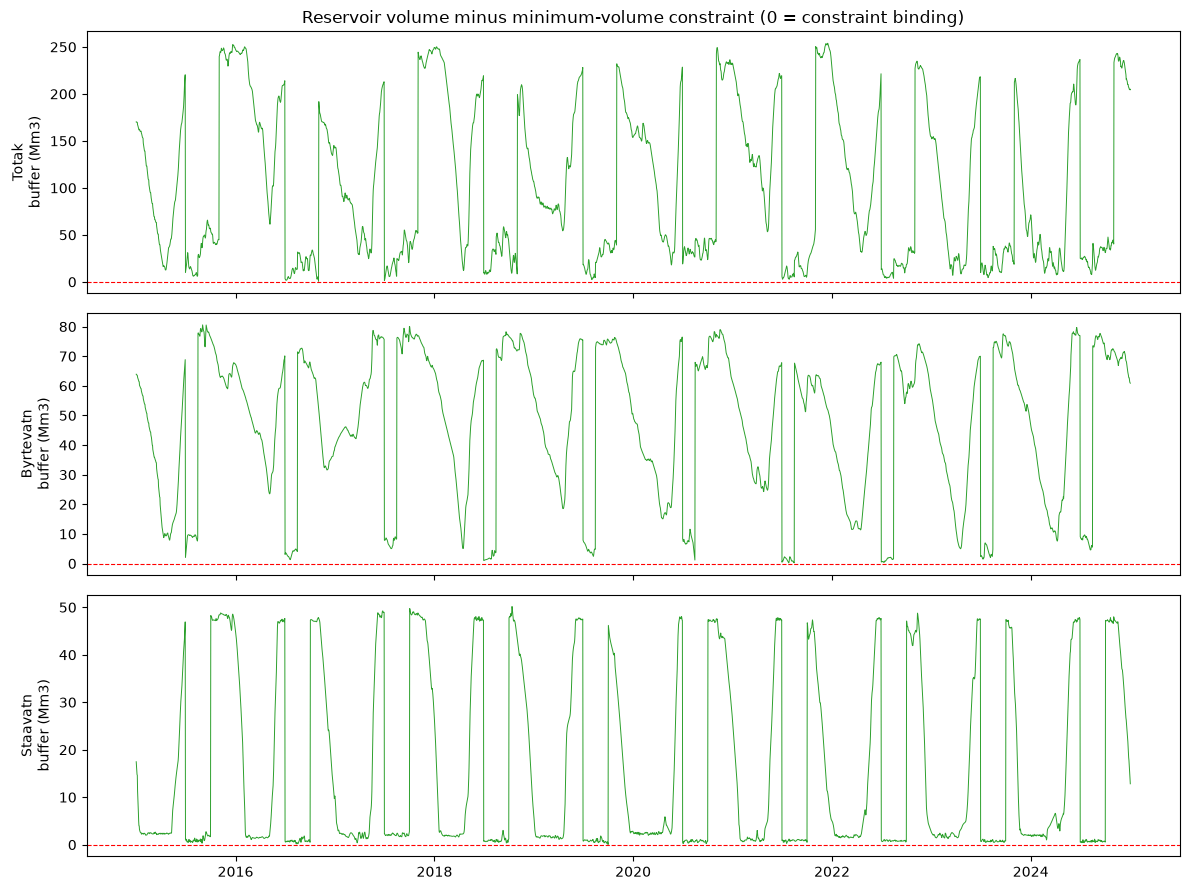

Fraction of days with buffer < 1 Mm3 (essentially at the floor):
Totak        0.000274
Byrtevatn    0.010947
Staavatn     0.208265
dtype: float64


In [11]:
common_dates = np.intersect1d(volume_dates, mv_dates)
v_idx = np.searchsorted(volume_dates, common_dates)
m_idx = np.searchsorted(mv_dates, common_dates)
buffer = pd.DataFrame(
    volume_values[v_idx][:, [volume_cols.index(c) for c in mv_cols]] - mv_values[m_idx],
    columns=mv_cols, index=common_dates,
)

fig, axes = plt.subplots(len(mv_cols), 1, figsize=(12, 3 * len(mv_cols)), sharex=True)
for ax, col in zip(axes, mv_cols):
    ax.plot(buffer.index, buffer[col], linewidth=0.7, color="tab:green")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set_ylabel(f"{col}\nbuffer (Mm3)")
axes[0].set_title("Reservoir volume minus minimum-volume constraint (0 = constraint binding)")
fig.tight_layout()
plt.show()

print("Fraction of days with buffer < 1 Mm3 (essentially at the floor):")
print((buffer < 1.0).mean())

All three reservoirs show a clear seasonal sawtooth: drawn down toward the floor over
winter/spring and refilled in summer, repeating every year. `Staavatn` is the most tightly managed --
its buffer sits under 1 Mm3 about **21% of days** (vs. ~1% for `Byrtevatn` and effectively 0% for
`Totak`), so for `Staavatn` specifically the minimum-volume constraint is a real, frequently-active
operating limit rather than a formality, and scenarios where `Staavatn` starts near its floor are
exactly where constraint-driven (rather than price-driven) commitment behavior should be expected.

## 11. Min-flow ecological constraint vs. natural inflow

`Constraint_min_flow.csv` columns (`b_Kjelavatn`, `b_Hyljelihyl`, `b_Vinjevatn`, `b_Byrtevatn`,
`b_Bandak`, `r_Vest_Vassdraget`) match inflow-dataset node names after stripping the `b_` prefix. The
constraint is a required *release* at that node; comparing it to natural inflow alone (before any
reservoir release) shows how often upstream regulation is doing real work to meet it, versus the river
clearing the bar on its own.

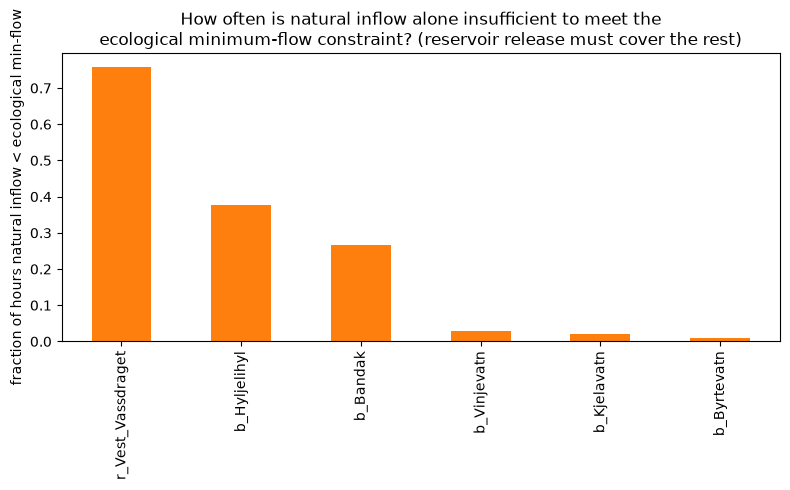

r_Vest_Vassdraget    0.757931
b_Hyljelihyl         0.376057
b_Bandak             0.266390
b_Vinjevatn          0.029154
b_Kjelavatn          0.019996
b_Byrtevatn          0.008872
dtype: float64

In [12]:
flow_node_map = {c: c[2:] if c.startswith("b_") else c for c in mf_cols}
common_dates = np.intersect1d(inflow_dates, mf_dates)
i_idx = np.searchsorted(inflow_dates, common_dates)
f_idx = np.searchsorted(mf_dates, common_dates)

shortfall_frac = {}
for mf_col, inflow_col in flow_node_map.items():
    required = mf_values[f_idx][:, mf_cols.index(mf_col)]
    actual = inflow_values[i_idx][:, inflow_cols.index(inflow_col)]
    shortfall_frac[mf_col] = float(np.mean(actual < required))
shortfall_frac = pd.Series(shortfall_frac).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
shortfall_frac.plot(kind="bar", ax=ax, color="tab:orange")
ax.set_ylabel("fraction of hours natural inflow < ecological min-flow")
ax.set_title("How often is natural inflow alone insufficient to meet the\n"
              "ecological minimum-flow constraint? (reservoir release must cover the rest)")
fig.tight_layout()
plt.show()

shortfall_frac

`r_Vest_Vassdraget` -- the confluence node downstream of `Lio`'s plant -- falls short of its
5 m3/s ecological minimum from natural inflow alone **76% of the time**, and `b_Hyljelihyl`/`b_Bandak`
fall short 38%/27% of the time. These are exactly the nodes where regulated releases from upstream
reservoirs are doing the real work of satisfying the ecological constraint, which is the expected
behavior for a regulated cascade -- it's a sanity check that passes, not an anomaly, but it does mean
a model should expect release-driven (not just inflow-driven) behavior to matter most for the plants
upstream of these three nodes (`Lio`, `Kjela`/`Vesle Kjela`, `Hogga`/`Tokke`).

## 12. Water-value redundancy (section 2.4) explained by cascade connectivity

Section 2.4 found several groups of exactly-identical water-value columns and left their physical
meaning as something to check. Build the undirected topology graph (reservoirs, rivers, tunnels,
plants as nodes) and measure the graph distance within each identical-value group.

In [13]:
identical_groups = []
seen = set()
for i, c1 in enumerate(wv_cols):
    if c1 in seen:
        continue
    group = [c1]
    for c2 in wv_cols[i + 1:]:
        if np.array_equal(wv_values[:, wv_cols.index(c1)], wv_values[:, wv_cols.index(c2)]):
            group.append(c2)
            seen.add(c2)
    if len(group) > 1:
        identical_groups.append(group)
        seen.add(c1)

G = nx.Graph()
for c in conns:
    G.add_edge(c["from"], c["to"])

print("Identical water-value column groups, and their shortest path through the topology graph:\n")
for group in identical_groups:
    print(group)
    for a_i in range(len(group)):
        for b_i in range(a_i + 1, len(group)):
            a, b = group[a_i], group[b_i]
            path = nx.shortest_path(G, a, b)
            print(f"  {a} <-> {b}: {len(path) - 1} hops via {path}")
    print()

Identical water-value column groups, and their shortest path through the topology graph:

['Kjelavatn', 'Staavatn']
  Kjelavatn <-> Staavatn: 2 hops via ['Kjelavatn', 's_Staavatn', 'Staavatn']

['Langesae', 'Foersvatn', 'Bordalsvatn']
  Langesae <-> Foersvatn: 2 hops via ['Langesae', 'r_Langesae', 'Foersvatn']
  Langesae <-> Bordalsvatn: 4 hops via ['Langesae', 's_Langesae', 'Foersvatn', 'Bordalsvatn_Foersvatn', 'Bordalsvatn']
  Foersvatn <-> Bordalsvatn: 2 hops via ['Foersvatn', 'Bordalsvatn_Foersvatn', 'Bordalsvatn']

['Venemo', 'Vaamarvatn', 'Totak', 'Hyljelihyl']
  Venemo <-> Vaamarvatn: 4 hops via ['Venemo', 'Venemo_Totak', 'Totak', 'Totak_Vaamarvatn', 'Vaamarvatn']
  Venemo <-> Totak: 2 hops via ['Venemo', 'Venemo_Totak', 'Totak']
  Venemo <-> Hyljelihyl: 2 hops via ['Venemo', 'r_Hyljelihyl', 'Hyljelihyl']
  Vaamarvatn <-> Totak: 2 hops via ['Vaamarvatn', 'Totak_Vaamarvatn', 'Totak']
  Vaamarvatn <-> Hyljelihyl: 4 hops via ['Vaamarvatn', 'b_Vaamarvatn', 'Vinjevatn', 'b_Hyljelihyl

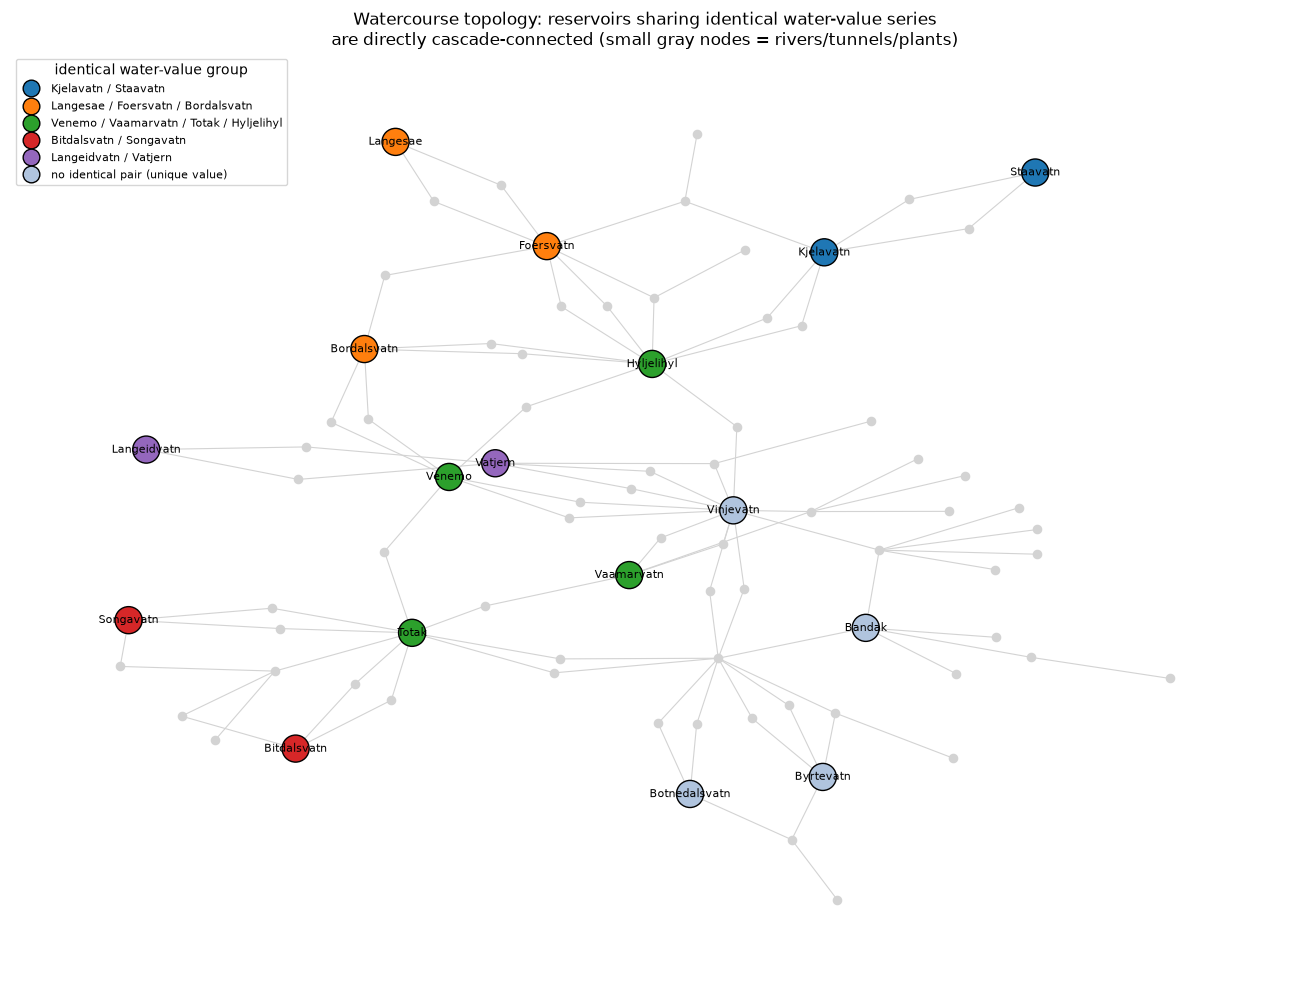

In [14]:
fig, ax = plt.subplots(figsize=(13, 10))
nx.draw_networkx_edges(G, pos := nx.kamada_kawai_layout(G), ax=ax, edge_color="lightgray", width=0.8)

node_type = {}
for c in conns:
    node_type[c["from"]] = c["from_type"]
    node_type[c["to"]] = c["to_type"]
reservoirs = [n for n, t in node_type.items() if t == "reservoir"]
other = [n for n in G.nodes if n not in reservoirs]

group_colors = plt.cm.tab10.colors
group_color = {r: group_colors[gi] for gi, group in enumerate(identical_groups) for r in group}
res_colors = [group_color.get(r, "lightsteelblue") for r in reservoirs]

nx.draw_networkx_nodes(G, pos, nodelist=other, node_size=35, node_color="lightgray", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=reservoirs, node_size=380, node_color=res_colors,
                        edgecolors="black", ax=ax)
nx.draw_networkx_labels(G, pos, labels={r: r for r in reservoirs}, font_size=8, ax=ax)

legend_handles = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=group_colors[gi],
               markeredgecolor="black", markersize=12, label=" / ".join(group))
    for gi, group in enumerate(identical_groups)
]
legend_handles.append(plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="lightsteelblue",
                                  markeredgecolor="black", markersize=12, label="no identical pair (unique value)"))
ax.legend(handles=legend_handles, loc="upper left", fontsize=8, title="identical water-value group")
ax.set_title("Watercourse topology: reservoirs sharing identical water-value series\n"
              "are directly cascade-connected (small gray nodes = rivers/tunnels/plants)")
ax.axis("off")
fig.tight_layout()
plt.show()

Every identical-value pair is directly cascade-connected -- 2 to 4 hops apart through a
connecting river or tunnel, with no other reservoir in between. This confirms the redundancy is
**not coincidental data duplication**: the synthetic water-value generator evidently assigns one
marginal value per hydraulically-coupled cascade segment (reservoirs connected by a river/tunnel with
no intervening storage of consequence) rather than a fully independent value per reservoir. For
modeling, this means the identical columns can safely be collapsed to one feature per cascade group
without losing information, and it also explains why `Vinje_G1`/`G2`/`G3` and the `Tokke_*` units see
correlated water-value signals even beyond their own reservoir in the section 7 heatmap -- the whole
`Vaamarvatn`/`Totak`/`Venemo`/`Hyljelihyl` and `Vinjevatn`-adjacent segments move together.

## 13. Summary

- **Water value is a strong, consistent predictor across every generator** (correlation -0.16 to
  -0.38 with each generator's own commitment rate), more consistent in sign than the price
  correlations reported in section 2.3, and the system-wide version (-0.33) rivals the strongest
  price feature found there.
- **The strong generator-pair commitment correlations from section 2.2 are mechanistic, not
  coincidental**: every top pair shares the same upstream reservoir via the topology graph.
- **Two reservoirs (`Vatjern`, `Hyljelihyl`) have zero recorded volume variance** -- their volume
  columns are dead weight as features (water value and inflow for the same reservoirs are still
  informative).
- **The min-volume constraint binds hardest at `Staavatn`** (buffer under 1 Mm3 on ~21% of days,
  vs. ~0-1% for `Totak`/`Byrtevatn`), making scenarios starting near its floor a plausible place to
  look for constraint-driven (rather than price-driven) commitment patterns.
- **The min-flow ecological constraint is frequently unmet by natural inflow alone**, especially at
  `r_Vest_Vassdraget` (76% of hours) and `b_Hyljelihyl` (38%) -- expected for a regulated system, and
  a sign that release behavior at the upstream plants (`Lio`, `Kjela`/`Vesle Kjela`) matters for
  meeting it.
- **The identical water-value column groups flagged in section 2.4 are cascade-connected reservoirs**
  (2-4 hops apart with no intervening storage), confirming they can be safely collapsed into one
  feature per cascade segment.

As with the price-based findings, these are associations, not causal claims -- but several (the
reservoir-pairing explanation, the volume data-quality issue, the cascade explanation for redundant
water-value columns) are concrete enough to act on directly in feature engineering, independent of
downstream model validation.